# ARG Chromosome vs. Plasmid Mapping

Pipeline step 2 for the ESKAPE AMR gene family project.

This notebook joins two analyses that already exist for each of the six ESKAPE pathogens, but that have never been connected to each other:

1. **RGI/CARD** (`CARD_Results/`) — which antimicrobial resistance genes (ARGs) each genome has, and which contig each one sits on.
2. **MOB-suite** (`Results/*_Mob_Results/`) — for the same genome assemblies, which contigs are chromosomal vs. plasmid, and for plasmid contigs, whether that plasmid is conjugative, mobilizable, or non-mobilizable.

For every ARG hit found by RGI, this notebook looks up which contig it is on, then looks up in the MOB-suite output whether that contig is chromosomal or plasmid-borne, and if plasmid-borne, how mobile that plasmid is.

**Design choices, deliberately:**
- Each organism's data is loaded into its own explicitly named variables (`AB_rgi_df`, `EF_contig_df`, …) — nothing is hidden inside a loop or a black-box function, so every intermediate result can be inspected after running.
- Klebsiella pneumoniae (Kp) has a different RGI contig-ID naming convention than the other five pathogens, and gets its own dedicated cells to load, verify, and resolve that convention, rather than being silently handled by a generic fallback.
- A reproducibility cell at the top records the exact Python/package versions this notebook was run with.

**Note:** This notebook only defines the pipeline; no cells have been run yet (aside from earlier interactive checks of the setup cell).

## 0. Reproducibility: environment and package versions

Record the exact Python and package versions this notebook is run with, so results can be regenerated later in a matching environment. (This is about *this analysis notebook's* environment — the upstream RGI/CARD and MOB-suite tool versions that produced the input data are tracked separately.)

In [1]:

import sys
import pandas as pd
import matplotlib
print(f'Python      : {sys.version.split()[0]}')
print(f'pandas      : {pd.__version__}')
print(f'matplotlib  : {matplotlib.__version__}')

Python      : 3.12.12
pandas      : 2.3.3
matplotlib  : 3.10.8


## 1. Configuration

In [2]:
# Standard library imports used for file discovery and path handling.
import os
import glob
import warnings
warnings.filterwarnings('ignore')

# Project root and the dedicated output folder for this notebook's results.
BASE_DIR = '/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family'
RESULTS_DIR = os.path.join(BASE_DIR, 'Results/Mobsuite')

# Create the output folder if it doesn't exist yet; to_csv/savefig do not create directories themselves.
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Directory is ready at: {RESULTS_DIR}")

Directory is ready at: /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite


Organism code -> (RGI results directory, MOB-suite results directory, full species name).

The MOB-suite folder-name casing is inconsistent across organisms (`kp_Mob_Results` lowercase, `PA_Mob_Results` uppercase, `Ent_Mob_Results` title-case), which is why this mapping is hardcoded here rather than derived programmatically from the organism code. Genome counts on the RGI side and the MOB-suite side have been confirmed to match exactly for all six organisms (checked separately before writing this notebook).

In [9]:
# Organism code -> (RGI results dir, MOB-suite results dir, full species name).
# Paths are relative to BASE_DIR; joined with os.path.join wherever they're used below.
ORGANISMS = {
    'AB':  ('CARD_Results/AB_rgi_results',  'Results/AB_Mob_Results',  'Acinetobacter baumannii'),
    'EF':  ('CARD_Results/EF_rgi_results',  'Results/EF_Mob_Results',  'Enterococcus faecium'),
    'ENT': ('CARD_Results/ENT_rgi_results', 'Results/Ent_Mob_Results', 'Enterobacter spp.'),
    'Kp':  ('CARD_Results/Kp_rgi_results',  'Results/kp_Mob_Results',  'Klebsiella pneumoniae'),
    'Pa':  ('CARD_Results/Pa_rgi_results',  'Results/PA_Mob_Results',  'Pseudomonas aeruginosa'),
    'SA':  ('CARD_Results/SA_rgi_results',  'Results/SA_Mob_Results',  'Staphylococcus aureus'),
}

## 2. Shared file-loading helpers

These three functions only do file I/O (reading RGI/MOB-suite files into dataframes) — they are not part of the analysis logic itself, so they're kept as small reusable helpers rather than repeated six times. The actual join/analysis for each organism is done explicitly in its own section below, not inside a function.

In [10]:
def load_rgi_hits(rgi_dir):
    """
    Load every genome's RGI hit file for one organism into a single dataframe.

    RGI writes one .txt file per genome (CARD_Results/<Org>_rgi_results/<accession>/<accession>.txt).
    The genome accession is only present in the file path, not as a column inside the file,
    so it's extracted from the filename and added as 'sample_id' here.
    """
    files = glob.glob(os.path.join(rgi_dir, '*', '*.txt'))
    frames = []
    for f in files:
        d = pd.read_csv(f, sep='\t')
        d['sample_id'] = os.path.basename(f).removesuffix('.txt')
        frames.append(d)
    rgi_df = pd.concat(frames, ignore_index=True)
    # Keep only the columns needed downstream.
    return rgi_df[['sample_id', 'Contig', 'Start', 'Stop', 'Best_Hit_ARO', 'Drug Class', 'AMR Gene Family']]

In [11]:
def load_mob_contig_report(mob_dir):
    """
    Load one organism's MOB-suite contig-level chromosome/plasmid calls.

    Reads the pre-aggregated summary/master_contig_report.tsv (one row per contig,
    across every genome for this organism) rather than looping over per-genome files.
    """
    contig_df = pd.read_csv(os.path.join(mob_dir, 'summary', 'master_contig_report.tsv'), sep='\t')
    return contig_df[['sample_id', 'contig_id', 'molecule_type', 'primary_cluster_id']]

In [12]:
def load_mob_mobtyper_results(mob_dir):
    """
    Load one organism's MOB-suite plasmid mobility calls.

    Reads summary/master_mobtyper_results.tsv (one row per assembled plasmid, keyed by
    primary_cluster_id) to get predicted_mobility: conjugative / mobilizable / non-mobilizable.
    """
    mobtyper_df = pd.read_csv(os.path.join(mob_dir, 'summary', 'master_mobtyper_results.tsv'), sep='\t')
    return mobtyper_df[['sample_id', 'primary_cluster_id', 'predicted_mobility']]

## 3. Contig-ID resolvers — two explicit conventions

RGI's `Contig` column is derived from Prodigal ORF headers, not read directly from the assembly. For five of the six organisms this mangles the accession's version dot into an underscore (`NZ_CP112545.1` -> `NZ_CP112545_1`). **Klebsiella pneumoniae (Kp) is the exception**: its RGI runs preserve the dot as-is. This was verified empirically (100 sampled genomes per organism, checked against the real MOB-suite contig sets, zero mismatches) before writing this notebook — there is no installed skill covering MOB-suite/RGI file formats to check this against.

Rather than one generic function that silently tries both conventions, there are two separate resolvers below, so which convention applies to which organism is visible in the code, not inferred at runtime.

In [13]:
def resolve_contig_id_dot_to_underscore(rgi_contig, mob_contig_set):
    """
    Contig-ID resolver for AB, EF, ENT, Pa, SA.

    These five organisms' RGI runs replace the accession's version dot with an underscore,
    e.g. 'NZ_CP112545.1' -> 'NZ_CP112545_1'. Converting only the LAST underscore back to a dot
    (not a blanket replace) correctly reverses this, since accession prefixes like 'NZ_' already
    contain a legitimate underscore of their own that must be left alone.
    """
    idx = rgi_contig.rfind('_')
    if idx == -1:
        return None
    candidate = rgi_contig[:idx] + '.' + rgi_contig[idx + 1:]
    return candidate if candidate in mob_contig_set else None

In [14]:
def resolve_contig_id_klebsiella(rgi_contig, mob_contig_set):
    """
    Contig-ID resolver for Klebsiella pneumoniae (Kp) only.

    Kp's RGI runs preserve the accession dot as-is (no Prodigal-style mangling seen in the
    other five organisms), so this is a direct lookup with no transform.
    """
    return rgi_contig if rgi_contig in mob_contig_set else None

## 4. Per-organism processing

The same four steps — load, resolve, join, save — are repeated explicitly for each of the six organisms below, each in its own section with its own named variables (`AB_rgi_df`, `AB_mapped_df`, etc.), rather than in a loop. Klebsiella's section has one extra step: a dedicated cell that verifies its different contig-ID convention on this dataset before resolving, instead of assuming it.

### 4.1 Acinetobacter baumannii (AB)

In [83]:
# Load Acinetobacter baumannii (AB) RGI hits and MOB-suite tables into their own named variables.
AB_rgi_df = load_rgi_hits(os.path.join(BASE_DIR, 'CARD_Results/AB_rgi_results'))
AB_contig_df = load_mob_contig_report(os.path.join(BASE_DIR, 'Results/AB_Mob_Results'))
AB_mobtyper_df = load_mob_mobtyper_results(os.path.join(BASE_DIR, 'Results/AB_Mob_Results'))

print(f'AB: {len(AB_rgi_df)} RGI hits, {len(AB_contig_df)} MOB-suite contigs, '
      f'{len(AB_mobtyper_df)} MOB-suite plasmids loaded')

AB: 31488 RGI hits, 2714 MOB-suite contigs, 1234 MOB-suite plasmids loaded


In [84]:
# Resolve each AB RGI contig ID against its own genome's MOB-suite contig set.
AB_contig_sets_by_sample = AB_contig_df.groupby('sample_id')['contig_id'].apply(set).to_dict()
AB_rgi_df['resolved_contig_id'] = AB_rgi_df.apply(
    lambda row: resolve_contig_id_dot_to_underscore(row['Contig'], AB_contig_sets_by_sample.get(row['sample_id'], set())),
    axis=1,
)

# Sanity check: how many RGI hits failed to resolve to a MOB-suite contig? Expected: 0.
AB_n_in = len(AB_rgi_df)
AB_n_unresolved = int(AB_rgi_df['resolved_contig_id'].isna().sum())
print(f'AB: {AB_n_in} RGI hits, {AB_n_unresolved} unresolved contigs')

AB: 31488 RGI hits, 0 unresolved contigs


In [85]:
# Join onto the MOB-suite contig table to attach molecule_type (chromosome/plasmid) + primary_cluster_id.
AB_joined_df = AB_rgi_df.merge(
    AB_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# For plasmid-borne hits, attach predicted_mobility via primary_cluster_id; chromosomal hits get a fixed label.
AB_joined_df = AB_joined_df.merge(
    AB_mobtyper_df,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
AB_joined_df.loc[AB_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# Final tidy per-hit table: one row per ARG hit with its chromosome/plasmid + mobility label.
AB_mapped_df = AB_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'predicted_mobility']
]
AB_mapped_df.insert(0, 'Organism', 'Acinetobacter baumannii')
print(f'AB: {len(AB_mapped_df)} rows in AB_mapped_df')

AB: 31488 rows in AB_mapped_df


In [86]:
# Correction: the AB_mapped_df built in the cell above doesn't retain primary_cluster_id in
# the final saved table. primary_cluster_id is already present in AB_joined_df (attached
# during the first merge with AB_contig_df) -- it's just not in the final column selection.
# This does NOT touch or fix the still-broken predicted_mobility column (see the separate,
# already-understood mobtyper sample_id bug) -- it only adds primary_cluster_id so
# AB_ARG_Location_Mapping.csv can be joined externally against the already-corrected
# AB_Contig_Chromosome_Plasmid_Mobility.csv to attach mobility information separately.
AB_mapped_df = AB_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class',
     'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]
AB_mapped_df.insert(0, 'Organism', 'Acinetobacter baumannii')
print(f'AB: {len(AB_mapped_df)} rows in AB_mapped_df (now including primary_cluster_id)')

AB: 31488 rows in AB_mapped_df (now including primary_cluster_id)


In [14]:
# Save this organism's per-hit chromosome/plasmid + mobility mapping.
AB_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'AB_ARG_Location_Mapping.csv'), index=False)

In [15]:
import pandas as pd 
Ab_df = pd.read_csv('/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite/AB_ARG_Location_Mapping.csv' )
Ab_df.head().style


,Organism,sample_id,Contig,AMR gene name,AMR Gene Family,Drug Class,molecule_type,primary_cluster_id,predicted_mobility
0,Acinetobacter baumannii,GCF_008807055.1,NZ_CP032743_1,Acinetobacter baumannii AmvA,major facilitator superfamily (MFS) antibiotic efflux pump,macrolide antibiotic; disinfecting agents and antiseptics,chromosome,-,n/a (chromosomal)
1,Acinetobacter baumannii,GCF_008807055.1,NZ_CP032743_1,adeN,resistance-nodulation-cell division (RND) antibiotic efflux pump,macrolide antibiotic; fluoroquinolone antibiotic; lincosamide antibiotic; carbapenem; cephalosporin; penicillin beta-lactam; tetracycline antibiotic; rifamycin antibiotic; diaminopyrimidine antibiotic; phenicol antibiotic,chromosome,-,n/a (chromosomal)
2,Acinetobacter baumannii,GCF_008807055.1,NZ_CP032743_1,Acinetobacter baumannii AbaQ,major facilitator superfamily (MFS) antibiotic efflux pump,fluoroquinolone antibiotic,chromosome,-,n/a (chromosomal)
3,Acinetobacter baumannii,GCF_008807055.1,NZ_CP032743_1,adeS,resistance-nodulation-cell division (RND) antibiotic efflux pump,glycylcycline; tetracycline antibiotic,chromosome,-,n/a (chromosomal)
4,Acinetobacter baumannii,GCF_008807055.1,NZ_CP032743_1,adeR,resistance-nodulation-cell division (RND) antibiotic efflux pump,glycylcycline; tetracycline antibiotic,chromosome,-,n/a (chromosomal)


In [1]:
import pandas as pd 
Ab_mobsuite = pd.read_csv('/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite/Plasmid_classification/AB_Contig_Chromosome_Plasmid_Mobility.csv' )
Ab_mobsuite.head().style


,sample_id,contig_id,molecule_type,primary_cluster_id,predicted_mobility
0,GCA_014880215.2,CP081137.1,chromosome,-,n/a (chromosomal)
1,GCA_014880215.2,CP081138.1,plasmid,AC163,non-mobilizable
2,GCA_014881055.2,CP081139.1,chromosome,-,n/a (chromosomal)
3,GCA_014881055.2,CP081140.1,plasmid,AB082,conjugative
4,GCA_014881055.2,CP081141.1,plasmid,AG958,mobilizable


In [87]:
# Bring in correct predicted_mobility from the already-fixed, contig-level mobility table
# (AB_Contig_Chromosome_Plasmid_Mobility.csv, built and verified in Mobsuite_Chromosome_Plasmid_Mobility.ipynb),
# rather than relying on this notebook's still-broken mobtyper join.
#
# Two things this has to guard against (checked against the data first):
# 1. primary_cluster_id == '-' for every chromosome row in both tables -- if not excluded,
#    every chromosome row would spuriously match every other chromosome row on that shared
#    placeholder. Chromosome rows already correctly say 'n/a (chromosomal)' and are excluded here.
# 2. A single assembled plasmid can span multiple contigs (157 of AB's 1,234 plasmids do),
#    so the mobility-reference table can have more than one row per (sample_id,
#    primary_cluster_id) -- deduplicated here so the merge can't multiply ARG-hit rows.
import pandas as pd
import os
ab_mobility_reference = pd.read_csv(
    os.path.join(RESULTS_DIR, 'Plasmid_classification', 'AB_Contig_Chromosome_Plasmid_Mobility.csv')
)
ab_mobility_reference = ab_mobility_reference[ab_mobility_reference['primary_cluster_id'] != '-']
ab_mobility_reference = ab_mobility_reference.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])
ab_mobility_reference = ab_mobility_reference[['sample_id', 'primary_cluster_id', 'predicted_mobility']]

n_before = len(AB_mapped_df)
AB_mapped_df = AB_mapped_df.merge(
    ab_mobility_reference,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
    suffixes=('', '_corrected'),
)
# Fill only the blanks (plasmid rows); chromosome rows' 'n/a (chromosomal)' is untouched
# since they never matched anything in ab_mobility_reference (no '-' rows in it).
AB_mapped_df['predicted_mobility'] = AB_mapped_df['predicted_mobility'].fillna(AB_mapped_df['predicted_mobility_corrected'])
AB_mapped_df = AB_mapped_df.drop(columns=['predicted_mobility_corrected'])

assert len(AB_mapped_df) == n_before, "Row count changed -- duplicate cluster IDs slipped through"
n_blank = int((AB_mapped_df.loc[AB_mapped_df['molecule_type'] == 'plasmid', 'predicted_mobility']).isna().sum())
print(f'AB: {len(AB_mapped_df)} rows, {n_blank} plasmid rows still blank (expect 0)')

AB: 31488 rows, 0 plasmid rows still blank (expect 0)


In [17]:
# Re-save AB_ARG_Location_Mapping.csv now that predicted_mobility has been corrected.
AB_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'AB_ARG_Location_Mapping1.csv'), index=False)

### 4.2 Enterococcus faecium (EF)

In [15]:
# Load Enterococcus faecium (EF) RGI hits and MOB-suite tables into their own named variables.
EF_rgi_df = load_rgi_hits(os.path.join(BASE_DIR, 'CARD_Results/EF_rgi_results'))
EF_contig_df = load_mob_contig_report(os.path.join(BASE_DIR, 'Results/EF_Mob_Results'))
EF_mobtyper_df = load_mob_mobtyper_results(os.path.join(BASE_DIR, 'Results/EF_Mob_Results'))

print(f'EF: {len(EF_rgi_df)} RGI hits, {len(EF_contig_df)} MOB-suite contigs, '
      f'{len(EF_mobtyper_df)} MOB-suite plasmids loaded')

EF: 12419 RGI hits, 4425 MOB-suite contigs, 2416 MOB-suite plasmids loaded


In [16]:
# Resolve each EF RGI contig ID against its own genome's MOB-suite contig set.
EF_contig_sets_by_sample = EF_contig_df.groupby('sample_id')['contig_id'].apply(set).to_dict()
EF_rgi_df['resolved_contig_id'] = EF_rgi_df.apply(
    lambda row: resolve_contig_id_dot_to_underscore(row['Contig'], EF_contig_sets_by_sample.get(row['sample_id'], set())),
    axis=1,
)

# Sanity check: how many RGI hits failed to resolve to a MOB-suite contig? Expected: 0.
EF_n_in = len(EF_rgi_df)
EF_n_unresolved = int(EF_rgi_df['resolved_contig_id'].isna().sum())
print(f'EF: {EF_n_in} RGI hits, {EF_n_unresolved} unresolved contigs')

EF: 12419 RGI hits, 0 unresolved contigs


In [17]:
# Join onto the MOB-suite contig table to attach molecule_type (chromosome/plasmid) + primary_cluster_id.
EF_joined_df = EF_rgi_df.merge(
    EF_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# For plasmid-borne hits, attach predicted_mobility via primary_cluster_id; chromosomal hits get a fixed label.
EF_joined_df = EF_joined_df.merge(
    EF_mobtyper_df,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
EF_joined_df.loc[EF_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# Final tidy per-hit table: one row per ARG hit with its chromosome/plasmid + mobility label.
EF_mapped_df = EF_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'predicted_mobility']
]
EF_mapped_df.insert(0, 'Organism', 'Enterococcus faecium')
print(f'EF: {len(EF_mapped_df)} rows in EF_mapped_df')

EF: 12419 rows in EF_mapped_df


In [23]:
EF_mapped_df = EF_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class',
     'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]

In [12]:
# Save this organism's per-hit chromosome/plasmid + mobility mapping.
EF_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'EF_ARG_Location_Mapping.csv'), index=False)

In [96]:
import pandas as pd 
EF_df = pd.read_csv('/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite/EF_ARG_Location_Mapping1.csv' )
EF_df.head().style


,sample_id,Contig,AMR gene name,AMR Gene Family,Drug Class,molecule_type,primary_cluster_id,predicted_mobility
0,GCF_043728825.1,NZ_CP112545_1,tet(M),tetracycline-resistant ribosomal protection protein,tetracycline antibiotic,chromosome,-,n/a (chromosomal)
1,GCF_043728825.1,NZ_CP112545_1,dfrG,trimethoprim resistant dihydrofolate reductase dfr,diaminopyrimidine antibiotic,chromosome,-,n/a (chromosomal)
2,GCF_043728825.1,NZ_CP112545_1,tet(M),tetracycline-resistant ribosomal protection protein,tetracycline antibiotic,chromosome,-,n/a (chromosomal)
3,GCF_043728825.1,NZ_CP112545_1,tet(M),tetracycline-resistant ribosomal protection protein,tetracycline antibiotic,chromosome,-,n/a (chromosomal)
4,GCF_043728825.1,NZ_CP112545_1,tet(45),major facilitator superfamily (MFS) antibiotic efflux pump,tetracycline antibiotic,chromosome,-,n/a (chromosomal)


In [24]:
import pandas as pd
import os
mobility_reference = pd.read_csv(
    os.path.join(RESULTS_DIR, 'Plasmid_classification', 'EF_Contig_Chromosome_Plasmid_Mobility.csv')
)
mobility_reference = mobility_reference[mobility_reference['primary_cluster_id'] != '-']
mobility_reference = mobility_reference.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])
mobility_reference = mobility_reference[['sample_id', 'primary_cluster_id', 'predicted_mobility']]

n_before = len(EF_mapped_df)
EF_mapped_df = EF_mapped_df.merge(
    mobility_reference,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
    suffixes=('', '_corrected'),
)
# Fill only the blanks (plasmid rows); chromosome rows' 'n/a (chromosomal)' is untouched
# since they never matched anything in ab_mobility_reference (no '-' rows in it).
EF_mapped_df['predicted_mobility'] = EF_mapped_df['predicted_mobility'].fillna(EF_mapped_df['predicted_mobility_corrected'])
EF_mapped_df = EF_mapped_df.drop(columns=['predicted_mobility_corrected'])

assert len(EF_mapped_df) == n_before, "Row count changed -- duplicate cluster IDs slipped through"
n_blank = int((EF_mapped_df.loc[EF_mapped_df['molecule_type'] == 'plasmid', 'predicted_mobility']).isna().sum())
print(f'EF: {len(EF_mapped_df)} rows, {n_blank} plasmid rows still blank (expect 0)')

EF: 12419 rows, 0 plasmid rows still blank (expect 0)


In [36]:

EF_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'EF_ARG_Location_Mapping1.csv'), index=False)

In [25]:
EF_mapped_df.columns.tolist()

['sample_id',
 'Contig',
 'AMR gene name',
 'AMR Gene Family',
 'Drug Class',
 'molecule_type',
 'primary_cluster_id',
 'predicted_mobility']

### 4.3 Enterobacter spp. (ENT)

In [48]:
# Load Enterobacter spp. (ENT) RGI hits and MOB-suite tables into their own named variables.
ENT_rgi_df = load_rgi_hits(os.path.join(BASE_DIR, 'CARD_Results/ENT_rgi_results'))
ENT_contig_df = load_mob_contig_report(os.path.join(BASE_DIR, 'Results/Ent_Mob_Results'))
ENT_mobtyper_df = load_mob_mobtyper_results(os.path.join(BASE_DIR, 'Results/Ent_Mob_Results'))

print(f'ENT: {len(ENT_rgi_df)} RGI hits, {len(ENT_contig_df)} MOB-suite contigs, '
      f'{len(ENT_mobtyper_df)} MOB-suite plasmids loaded')

ENT: 25667 RGI hits, 2316 MOB-suite contigs, 1336 MOB-suite plasmids loaded


In [49]:
# Resolve each ENT RGI contig ID against its own genome's MOB-suite contig set.
ENT_contig_sets_by_sample = ENT_contig_df.groupby('sample_id')['contig_id'].apply(set).to_dict()
ENT_rgi_df['resolved_contig_id'] = ENT_rgi_df.apply(
    lambda row: resolve_contig_id_dot_to_underscore(row['Contig'], ENT_contig_sets_by_sample.get(row['sample_id'], set())),
    axis=1,
)

# Sanity check: how many RGI hits failed to resolve to a MOB-suite contig? Expected: 0.
ENT_n_in = len(ENT_rgi_df)
ENT_n_unresolved = int(ENT_rgi_df['resolved_contig_id'].isna().sum())
print(f'ENT: {ENT_n_in} RGI hits, {ENT_n_unresolved} unresolved contigs')

ENT: 25667 RGI hits, 0 unresolved contigs


In [50]:
# Join onto the MOB-suite contig table to attach molecule_type (chromosome/plasmid) + primary_cluster_id.
ENT_joined_df = ENT_rgi_df.merge(
    ENT_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# For plasmid-borne hits, attach predicted_mobility via primary_cluster_id; chromosomal hits get a fixed label.
ENT_joined_df = ENT_joined_df.merge(
    ENT_mobtyper_df,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
ENT_joined_df.loc[ENT_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# Final tidy per-hit table: one row per ARG hit with its chromosome/plasmid + mobility label.
ENT_mapped_df = ENT_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'predicted_mobility']
]
ENT_mapped_df.insert(0, 'Organism', 'Enterobacter spp.')
print(f'ENT: {len(ENT_mapped_df)} rows in ENT_mapped_df')

ENT: 25667 rows in ENT_mapped_df


In [51]:
ENT_mapped_df = ENT_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class',
     'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]

In [53]:
# Save this organism's per-hit chromosome/plasmid + mobility mapping.
ENT_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'ENT_ARG_Location_Mapping.csv'), index=False)

In [46]:
import pandas as pd
import os

# 1. Join onto the MOB-suite contig table
ENT_joined_df = ENT_rgi_df.merge(
    ENT_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# 2. Fix the row mismatch: Deduplicate the mobtyper dataframe before merging
ENT_mobtyper_unique = ENT_mobtyper_df.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])

ENT_joined_df = ENT_joined_df.merge(
    ENT_mobtyper_unique,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
ENT_joined_df.loc[ENT_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# 3. Fix the missing column: Retain 'primary_cluster_id'
ENT_mapped_df = ENT_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]
ENT_mapped_df.insert(0, 'Organism', 'Enterobacter spp.')
print(f'ENT: {len(ENT_mapped_df)} rows in ENT_mapped_df (after initial merge)')

# 4. Execute the correction merge
mobility_reference = pd.read_csv(
    os.path.join(RESULTS_DIR, 'Plasmid_classification', 'ENT_Contig_Chromosome_Plasmid_Mobility.csv')
)
mobility_reference = mobility_reference[mobility_reference['primary_cluster_id'] != '-']
mobility_reference = mobility_reference.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])
mobility_reference = mobility_reference[['sample_id', 'primary_cluster_id', 'predicted_mobility']]

n_before = len(ENT_mapped_df)
ENT_mapped_df = ENT_mapped_df.merge(
    mobility_reference,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
    suffixes=('', '_corrected'),
)

# Fill only the blanks (plasmid rows)
ENT_mapped_df['predicted_mobility'] = ENT_mapped_df['predicted_mobility'].fillna(ENT_mapped_df['predicted_mobility_corrected'])
ENT_mapped_df = ENT_mapped_df.drop(columns=['predicted_mobility_corrected'])

# 5. Final validation
assert len(ENT_mapped_df) == n_before, "Row count changed -- duplicate cluster IDs slipped through"
n_blank = int((ENT_mapped_df.loc[ENT_mapped_df['molecule_type'] == 'plasmid', 'predicted_mobility']).isna().sum())
print(f'ENT: {len(ENT_mapped_df)} final rows, {n_blank} plasmid rows still blank (expect 0)')

ENT: 25667 rows in ENT_mapped_df (after initial merge)
ENT: 25667 final rows, 0 plasmid rows still blank (expect 0)


In [47]:
ENT_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'ENT_ARG_Location_Mapping1.csv'), index=False)

### 4.4 Klebsiella pneumoniae (Kp)\n\nDifferent RGI contig-ID convention than the other five organisms — see the verification cell below.

In [60]:
# Load Klebsiella pneumoniae (Kp) RGI hits and MOB-suite tables into their own named variables.
Kp_rgi_df = load_rgi_hits(os.path.join(BASE_DIR, 'CARD_Results/Kp_rgi_results'))
Kp_contig_df = load_mob_contig_report(os.path.join(BASE_DIR, 'Results/kp_Mob_Results'))
Kp_mobtyper_df = load_mob_mobtyper_results(os.path.join(BASE_DIR, 'Results/kp_Mob_Results'))

print(f'Kp: {len(Kp_rgi_df)} RGI hits, {len(Kp_contig_df)} MOB-suite contigs, '
      f'{len(Kp_mobtyper_df)} MOB-suite plasmids loaded')

Kp: 179223 RGI hits, 17423 MOB-suite contigs, 10875 MOB-suite plasmids loaded


In [61]:
# Verify Kp's contig-ID convention on this dataset rather than assuming it: sample some Kp
# contigs and check what fraction already match a MOB-suite contig_id directly (no transform).
Kp_contig_id_set = set(Kp_contig_df['contig_id'])
Kp_sample_contigs = Kp_rgi_df['Contig'].drop_duplicates().sample(n=min(500, len(Kp_rgi_df)), random_state=0)
Kp_direct_match_rate = Kp_sample_contigs.isin(Kp_contig_id_set).mean()

print(f'Kp: {Kp_direct_match_rate:.1%} of a {len(Kp_sample_contigs)}-contig sample matched a MOB-suite '
      f'contig_id directly (dot preserved, no underscore mangling) \u2014 expected close to 100%.')

Kp: 100.0% of a 500-contig sample matched a MOB-suite contig_id directly (dot preserved, no underscore mangling) — expected close to 100%.


In [62]:
# Resolve each Kp RGI contig ID against its own genome's MOB-suite contig set.
Kp_contig_sets_by_sample = Kp_contig_df.groupby('sample_id')['contig_id'].apply(set).to_dict()
Kp_rgi_df['resolved_contig_id'] = Kp_rgi_df.apply(
    lambda row: resolve_contig_id_klebsiella(row['Contig'], Kp_contig_sets_by_sample.get(row['sample_id'], set())),
    axis=1,
)

# Sanity check: how many RGI hits failed to resolve to a MOB-suite contig? Expected: 0.
Kp_n_in = len(Kp_rgi_df)
Kp_n_unresolved = int(Kp_rgi_df['resolved_contig_id'].isna().sum())
print(f'Kp: {Kp_n_in} RGI hits, {Kp_n_unresolved} unresolved contigs')

Kp: 179223 RGI hits, 0 unresolved contigs


In [63]:
# Join onto the MOB-suite contig table to attach molecule_type (chromosome/plasmid) + primary_cluster_id.
Kp_joined_df = Kp_rgi_df.merge(
    Kp_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# For plasmid-borne hits, attach predicted_mobility via primary_cluster_id; chromosomal hits get a fixed label.
Kp_joined_df = Kp_joined_df.merge(
    Kp_mobtyper_df,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
Kp_joined_df.loc[Kp_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# Final tidy per-hit table: one row per ARG hit with its chromosome/plasmid + mobility label.
Kp_mapped_df = Kp_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'predicted_mobility']
]
Kp_mapped_df.insert(0, 'Organism', 'Klebsiella pneumoniae')
print(f'Kp: {len(Kp_mapped_df)} rows in Kp_mapped_df')

Kp: 179223 rows in Kp_mapped_df


In [64]:
Kp_mapped_df = Kp_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class',
     'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]

In [66]:
import pandas as pd
import os

# 1. Join onto the MOB-suite contig table
Kp_joined_df = Kp_rgi_df.merge(
    Kp_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# 2. Fix the row mismatch: Deduplicate the mobtyper dataframe before merging
Kp_mobtyper_unique = Kp_mobtyper_df.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])

Kp_joined_df = Kp_joined_df.merge(
    Kp_mobtyper_unique,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
Kp_joined_df.loc[Kp_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# 3. Fix the missing column: Retain 'primary_cluster_id'
Kp_mapped_df = Kp_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]
Kp_mapped_df.insert(0, 'Organism', 'Klebsiella pneumoniae')
print(f'Kp: {len(Kp_mapped_df)} rows in Kp_mapped_df (after initial merge)')

# 4. Execute the correction merge
mobility_reference = pd.read_csv(
    os.path.join(RESULTS_DIR, 'Plasmid_classification', 'Kp_Contig_Chromosome_Plasmid_Mobility.csv')
)
mobility_reference = mobility_reference[mobility_reference['primary_cluster_id'] != '-']
mobility_reference = mobility_reference.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])
mobility_reference = mobility_reference[['sample_id', 'primary_cluster_id', 'predicted_mobility']]

n_before = len(Kp_mapped_df)
Kp_mapped_df = Kp_mapped_df.merge(
    mobility_reference,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
    suffixes=('', '_corrected'),
)

# Fill only the blanks (plasmid rows)
Kp_mapped_df['predicted_mobility'] = Kp_mapped_df['predicted_mobility'].fillna(Kp_mapped_df['predicted_mobility_corrected'])
Kp_mapped_df = Kp_mapped_df.drop(columns=['predicted_mobility_corrected'])

# 5. Final validation
assert len(Kp_mapped_df) == n_before, "Row count changed -- duplicate cluster IDs slipped through"
n_blank = int((Kp_mapped_df.loc[Kp_mapped_df['molecule_type'] == 'plasmid', 'predicted_mobility']).isna().sum())
print(f'Kp: {len(Kp_mapped_df)} final rows, {n_blank} plasmid rows still blank (expect 0)')

Kp: 179223 rows in Kp_mapped_df (after initial merge)
Kp: 179223 final rows, 0 plasmid rows still blank (expect 0)


In [67]:
# Save this organism's per-hit chromosome/plasmid + mobility mapping.
Kp_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'Kp_ARG_Location_Mapping1.csv'), index=False)

### 4.5 Pseudomonas aeruginosa (Pa)

In [68]:
# Load Pseudomonas aeruginosa (Pa) RGI hits and MOB-suite tables into their own named variables.
Pa_rgi_df = load_rgi_hits(os.path.join(BASE_DIR, 'CARD_Results/Pa_rgi_results'))
Pa_contig_df = load_mob_contig_report(os.path.join(BASE_DIR, 'Results/PA_Mob_Results'))
Pa_mobtyper_df = load_mob_mobtyper_results(os.path.join(BASE_DIR, 'Results/PA_Mob_Results'))

print(f'Pa: {len(Pa_rgi_df)} RGI hits, {len(Pa_contig_df)} MOB-suite contigs, '
      f'{len(Pa_mobtyper_df)} MOB-suite plasmids loaded')

Pa: 84443 RGI hits, 1889 MOB-suite contigs, 236 MOB-suite plasmids loaded


In [69]:
# Resolve each Pa RGI contig ID against its own genome's MOB-suite contig set.
Pa_contig_sets_by_sample = Pa_contig_df.groupby('sample_id')['contig_id'].apply(set).to_dict()
Pa_rgi_df['resolved_contig_id'] = Pa_rgi_df.apply(
    lambda row: resolve_contig_id_dot_to_underscore(row['Contig'], Pa_contig_sets_by_sample.get(row['sample_id'], set())),
    axis=1,
)

# Sanity check: how many RGI hits failed to resolve to a MOB-suite contig? Expected: 0.
Pa_n_in = len(Pa_rgi_df)
Pa_n_unresolved = int(Pa_rgi_df['resolved_contig_id'].isna().sum())
print(f'Pa: {Pa_n_in} RGI hits, {Pa_n_unresolved} unresolved contigs')

Pa: 84443 RGI hits, 0 unresolved contigs


In [70]:
# Join onto the MOB-suite contig table to attach molecule_type (chromosome/plasmid) + primary_cluster_id.
Pa_joined_df = Pa_rgi_df.merge(
    Pa_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# For plasmid-borne hits, attach predicted_mobility via primary_cluster_id; chromosomal hits get a fixed label.
Pa_joined_df = Pa_joined_df.merge(
    Pa_mobtyper_df,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
Pa_joined_df.loc[Pa_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# Final tidy per-hit table: one row per ARG hit with its chromosome/plasmid + mobility label.
Pa_mapped_df = Pa_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'predicted_mobility']
]
Pa_mapped_df.insert(0, 'Organism', 'Pseudomonas aeruginosa')
print(f'Pa: {len(Pa_mapped_df)} rows in Pa_mapped_df')

Pa: 84443 rows in Pa_mapped_df


In [71]:
Pa_mapped_df = Pa_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class',
     'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]

In [73]:
import pandas as pd
import os

# 1. Join onto the MOB-suite contig table
Pa_joined_df = Pa_rgi_df.merge(
    Pa_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# 2. Fix the row mismatch: Deduplicate the mobtyper dataframe before merging
# This ensures a strict 1:1 join that prevents artificial row inflation for plasmid hits
Pa_mobtyper_unique = Pa_mobtyper_df.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])

Pa_joined_df = Pa_joined_df.merge(
    Pa_mobtyper_unique,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
Pa_joined_df.loc[Pa_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# 3. Fix the missing column: Retain 'primary_cluster_id'
# Explicitly keeping this column allows the downstream correction script to locate the necessary keys
Pa_mapped_df = Pa_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]
Pa_mapped_df.insert(0, 'Organism', 'Pseudomonas aeruginosa')
print(f'Pa: {len(Pa_mapped_df)} rows in Pa_mapped_df (after initial merge)')

# 4. Execute the correction merge
mobility_reference = pd.read_csv(
    os.path.join(RESULTS_DIR, 'Plasmid_classification', 'Pa_Contig_Chromosome_Plasmid_Mobility.csv')
)
mobility_reference = mobility_reference[mobility_reference['primary_cluster_id'] != '-']
mobility_reference = mobility_reference.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])
mobility_reference = mobility_reference[['sample_id', 'primary_cluster_id', 'predicted_mobility']]

n_before = len(Pa_mapped_df)
Pa_mapped_df = Pa_mapped_df.merge(
    mobility_reference,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
    suffixes=('', '_corrected'),
)

# Fill only the blanks (plasmid rows) safely using the corrected mobility data
Pa_mapped_df['predicted_mobility'] = Pa_mapped_df['predicted_mobility'].fillna(Pa_mapped_df['predicted_mobility_corrected'])
Pa_mapped_df = Pa_mapped_df.drop(columns=['predicted_mobility_corrected'])

# 5. Final validation
# Asserts that the row count has not mutated and checks for any remaining unmapped plasmids
assert len(Pa_mapped_df) == n_before, "Row count changed -- duplicate cluster IDs slipped through"
n_blank = int((Pa_mapped_df.loc[Pa_mapped_df['molecule_type'] == 'plasmid', 'predicted_mobility']).isna().sum())
print(f'Pa: {len(Pa_mapped_df)} final rows, {n_blank} plasmid rows still blank (expect 0)')

Pa: 84443 rows in Pa_mapped_df (after initial merge)
Pa: 84443 final rows, 0 plasmid rows still blank (expect 0)


In [74]:
# Save this organism's per-hit chromosome/plasmid + mobility mapping.
Pa_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'Pa_ARG_Location_Mapping1.csv'), index=False)

### 4.6 Staphylococcus aureus (SA)

In [75]:
# Load Staphylococcus aureus (SA) RGI hits and MOB-suite tables into their own named variables.
SA_rgi_df = load_rgi_hits(os.path.join(BASE_DIR, 'CARD_Results/SA_rgi_results'))
SA_contig_df = load_mob_contig_report(os.path.join(BASE_DIR, 'Results/SA_Mob_Results'))
SA_mobtyper_df = load_mob_mobtyper_results(os.path.join(BASE_DIR, 'Results/SA_Mob_Results'))

print(f'SA: {len(SA_rgi_df)} RGI hits, {len(SA_contig_df)} MOB-suite contigs, '
      f'{len(SA_mobtyper_df)} MOB-suite plasmids loaded')

SA: 48251 RGI hits, 4246 MOB-suite contigs, 1639 MOB-suite plasmids loaded


In [76]:
# Resolve each SA RGI contig ID against its own genome's MOB-suite contig set.
SA_contig_sets_by_sample = SA_contig_df.groupby('sample_id')['contig_id'].apply(set).to_dict()
SA_rgi_df['resolved_contig_id'] = SA_rgi_df.apply(
    lambda row: resolve_contig_id_dot_to_underscore(row['Contig'], SA_contig_sets_by_sample.get(row['sample_id'], set())),
    axis=1,
)

# Sanity check: how many RGI hits failed to resolve to a MOB-suite contig? Expected: 0.
SA_n_in = len(SA_rgi_df)
SA_n_unresolved = int(SA_rgi_df['resolved_contig_id'].isna().sum())
print(f'SA: {SA_n_in} RGI hits, {SA_n_unresolved} unresolved contigs')

SA: 48251 RGI hits, 0 unresolved contigs


In [77]:
# Join onto the MOB-suite contig table to attach molecule_type (chromosome/plasmid) + primary_cluster_id.
SA_joined_df = SA_rgi_df.merge(
    SA_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# For plasmid-borne hits, attach predicted_mobility via primary_cluster_id; chromosomal hits get a fixed label.
SA_joined_df = SA_joined_df.merge(
    SA_mobtyper_df,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
SA_joined_df.loc[SA_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# Final tidy per-hit table: one row per ARG hit with its chromosome/plasmid + mobility label.
SA_mapped_df = SA_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'predicted_mobility']
]
SA_mapped_df.insert(0, 'Organism', 'Staphylococcus aureus')
print(f'SA: {len(SA_mapped_df)} rows in SA_mapped_df')

SA: 48251 rows in SA_mapped_df


In [78]:
SA_mapped_df = SA_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class',
     'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]

In [80]:
import pandas as pd
import os

# 1. Join onto the MOB-suite contig table
SA_joined_df = SA_rgi_df.merge(
    SA_contig_df,
    left_on=['sample_id', 'resolved_contig_id'],
    right_on=['sample_id', 'contig_id'],
    how='left',
)

# 2. Fix the row mismatch: Deduplicate the mobtyper dataframe before merging
# This ensures a strict 1:1 join that prevents artificial row inflation for plasmid hits
SA_mobtyper_unique = SA_mobtyper_df.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])

SA_joined_df = SA_joined_df.merge(
    SA_mobtyper_unique,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
)
SA_joined_df.loc[SA_joined_df['molecule_type'] != 'plasmid', 'predicted_mobility'] = 'n/a (chromosomal)'

# 3. Fix the missing column: Retain 'primary_cluster_id'
# Explicitly keeping this column allows the downstream correction script to locate the necessary keys
SA_mapped_df = SA_joined_df.rename(columns={'Best_Hit_ARO': 'AMR gene name'})[
    ['sample_id', 'Contig', 'AMR gene name', 'AMR Gene Family', 'Drug Class', 'molecule_type', 'primary_cluster_id', 'predicted_mobility']
]
SA_mapped_df.insert(0, 'Organism', 'Staphylococcus aureus')
print(f'SA: {len(SA_mapped_df)} rows in SA_mapped_df (after initial merge)')

# 4. Execute the correction merge
mobility_reference = pd.read_csv(
    os.path.join(RESULTS_DIR, 'Plasmid_classification', 'SA_Contig_Chromosome_Plasmid_Mobility.csv')
)
mobility_reference = mobility_reference[mobility_reference['primary_cluster_id'] != '-']
mobility_reference = mobility_reference.drop_duplicates(subset=['sample_id', 'primary_cluster_id'])
mobility_reference = mobility_reference[['sample_id', 'primary_cluster_id', 'predicted_mobility']]

n_before = len(SA_mapped_df)
SA_mapped_df = SA_mapped_df.merge(
    mobility_reference,
    on=['sample_id', 'primary_cluster_id'],
    how='left',
    suffixes=('', '_corrected'),
)

# Fill only the blanks (plasmid rows) safely using the corrected mobility data
SA_mapped_df['predicted_mobility'] = SA_mapped_df['predicted_mobility'].fillna(SA_mapped_df['predicted_mobility_corrected'])
SA_mapped_df = SA_mapped_df.drop(columns=['predicted_mobility_corrected'])

# 5. Final validation
# Asserts that the row count has not mutated and checks for any remaining unmapped plasmids
assert len(SA_mapped_df) == n_before, "Row count changed -- duplicate cluster IDs slipped through"
n_blank = int((SA_mapped_df.loc[SA_mapped_df['molecule_type'] == 'plasmid', 'predicted_mobility']).isna().sum())
print(f'SA: {len(SA_mapped_df)} final rows, {n_blank} plasmid rows still blank (expect 0)')

SA: 48251 rows in SA_mapped_df (after initial merge)
SA: 48251 final rows, 0 plasmid rows still blank (expect 0)


In [81]:
# Save this organism's per-hit chromosome/plasmid + mobility mapping.
SA_mapped_df.to_csv(os.path.join(RESULTS_DIR, 'SA_ARG_Location_Mapping1.csv'), index=False)

## 5. Cross-organism summary

Combine the six `<Org>_mapped_df` variables already in memory (no need to re-read from disk) into one table, then summarize per ARG gene family: the chromosome vs. plasmid split, and among plasmid-borne hits, the mobility-class split.

In [88]:
# Combine all six organisms' mapped tables into one, using the named variables already in memory.
combined_df = pd.concat(
    [AB_mapped_df, EF_mapped_df, ENT_mapped_df, Kp_mapped_df, Pa_mapped_df, SA_mapped_df],
    ignore_index=True,
)
combined_df.to_csv(os.path.join(RESULTS_DIR, 'ARG_Chromosome_Plasmid_Mapping.csv'), index=False)
print(f'Combined table: {len(combined_df)} ARG hits across all six organisms')

Combined table: 368243 ARG hits across all six organisms


In [89]:
# Per gene family: chromosome vs. plasmid counts and the % of hits that are plasmid-borne.
family_summary = (
    combined_df
    .groupby(['AMR Gene Family', 'molecule_type'])
    .size()
    .unstack(fill_value=0)
)
family_summary['pct_plasmid'] = (
    family_summary.get('plasmid', 0)
    / (family_summary.get('plasmid', 0) + family_summary.get('chromosome', 0))
    * 100
)
family_summary = family_summary.sort_values('pct_plasmid', ascending=False)
family_summary.to_csv(os.path.join(RESULTS_DIR, 'ARG_Family_Chromosome_Plasmid_Summary.csv'))

In [90]:
# Among plasmid-borne hits only: per gene family, how many are conjugative / mobilizable / non-mobilizable.
mobility_summary = (
    combined_df[combined_df['molecule_type'] == 'plasmid']
    .groupby(['AMR Gene Family', 'predicted_mobility'])
    .size()
    .unstack(fill_value=0)
)
mobility_summary.to_csv(os.path.join(RESULTS_DIR, 'ARG_Family_Mobility_Summary.csv'))

## 6. Sanity check against known AMR biology

Classic mobile carbapenemases (NDM, KPC, OXA-48-like) are expected, from the published literature, to be predominantly plasmid-borne and conjugative/mobilizable. If the join and mobility-classification logic are correct, this should show up here — an independent biological plausibility check, not just a technical one.

In [91]:
# Check whether known mobile carbapenemase families skew plasmid-borne, as expected.
known_mobile_carbapenemases = ['NDM beta-lactamase', 'KPC beta-lactamase', 'OXA-48-like beta-lactamase']
family_summary.loc[family_summary.index.intersection(known_mobile_carbapenemases)]

molecule_type,chromosome,plasmid,pct_plasmid
AMR Gene Family,,,
KPC beta-lactamase,172,1286,88.203018
NDM beta-lactamase,226,477,67.852063


## 7. Visualization

Chromosome vs. plasmid distribution across ARG gene families. Follow the `dataviz` skill's palette/design guidance before finalizing this chart (colors below are placeholders).

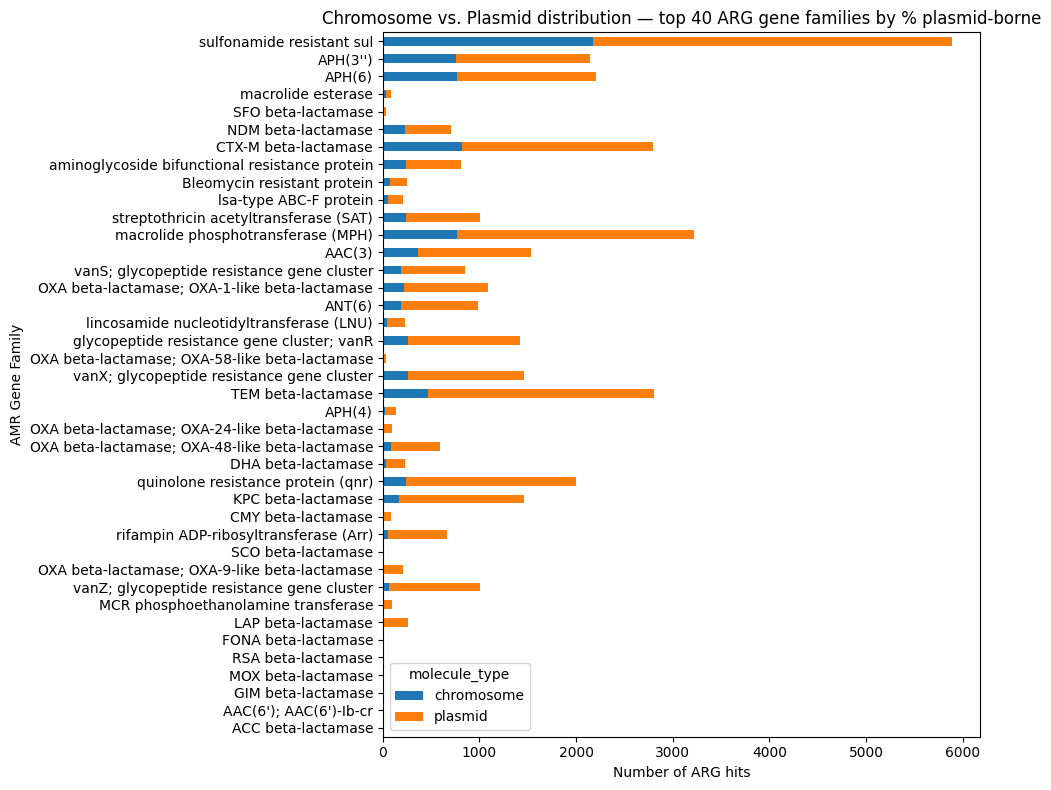

In [93]:
# Stacked bar chart: chromosome vs. plasmid hit counts for the top 20 gene families by % plasmid-borne.
import matplotlib.pyplot as plt

top_families = family_summary.head(40)
fig, ax = plt.subplots(figsize=(10, 8))
top_families[['chromosome', 'plasmid']].plot(kind='barh', stacked=True, ax=ax)
ax.set_xlabel('Number of ARG hits')
ax.set_title('Chromosome vs. Plasmid distribution \u2014 top 40 ARG gene families by % plasmid-borne')
plt.tight_layout()
#plt.savefig(os.path.join(RESULTS_DIR, 'ARG_Chromosome_Plasmid_barplot.png'), dpi=200)
plt.show()

In [101]:
import pandas as pd
import os

# Define the target directory where the individual CSVs are saved
RESULTS_DIR = '/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite'

# Define the exact list of pipeline files to merge
files_to_concat = [
    'AB_ARG_Location_Mapping1.csv',
    'EF_ARG_Location_Mapping1.csv',
    'ENT_ARG_Location_Mapping1.csv',
    'Kp_ARG_Location_Mapping1.csv',
    'Pa_ARG_Location_Mapping1.csv',
    'SA_ARG_Location_Mapping1.csv'
]

dataframes = []

# Loop through the list, read each CSV, and append to the list
for file_name in files_to_concat:
    file_path = os.path.join(RESULTS_DIR, file_name)
    
    # Check if the file exists before trying to read it to prevent FileNotFoundError
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        dataframes.append(df)
        print(f"Loaded: {file_name} ({len(df)} rows)")
    else:
        print(f"Warning: {file_name} not found in directory.")

# Concatenate all loaded dataframes vertically
# ignore_index=True resets the row numbers so they flow sequentially from 0 to N
combined_df = pd.concat(dataframes, ignore_index=True)

# Save the unified dataset to a new CSV file
output_path = os.path.join(RESULTS_DIR, 'ARG_Chromosome_Plasmid_Mapping.csv')
combined_df.to_csv(output_path, index=False)

print(f"\nSuccessfully created combined file: {output_path}")
print(f"Total rows in merged dataset: {len(combined_df)}")

Loaded: AB_ARG_Location_Mapping1.csv (31488 rows)
Loaded: EF_ARG_Location_Mapping1.csv (12419 rows)
Loaded: ENT_ARG_Location_Mapping1.csv (25667 rows)
Loaded: Kp_ARG_Location_Mapping1.csv (179223 rows)
Loaded: Pa_ARG_Location_Mapping1.csv (84443 rows)
Loaded: SA_ARG_Location_Mapping1.csv (48251 rows)

Successfully created combined file: /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite/ARG_Chromosome_Plasmid_Mapping.csv
Total rows in merged dataset: 381491


In [102]:
# Per gene family: chromosome vs. plasmid counts and the % of hits that are plasmid-borne.
family_summary = (
    combined_df
    .groupby(['AMR Gene Family', 'molecule_type'])
    .size()
    .unstack(fill_value=0)
)
family_summary['pct_plasmid'] = (
    family_summary.get('plasmid', 0)
    / (family_summary.get('plasmid', 0) + family_summary.get('chromosome', 0))
    * 100
)
family_summary = family_summary.sort_values('pct_plasmid', ascending=False)
family_summary.to_csv(os.path.join(RESULTS_DIR, 'ARG_Family_Chromosome_Plasmid_Summary.csv'))

In [103]:
import pandas as pd
import os

RESULTS_DIR = '/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite'

# Load the unified hit-level dataset
combined_df = pd.read_csv(os.path.join(RESULTS_DIR, 'ARG_Chromosome_Plasmid_Mapping.csv'))

# Generate the matrix: 
# Rows = ARG Families 
# Columns = Organism -> Mobility Class
mobility_matrix = pd.crosstab(
    index=combined_df['AMR Gene Family'],
    columns=[combined_df['Organism'], combined_df['predicted_mobility']],
    margins=True, # Adds an 'All' column and row for total dataset counts
    margins_name='Total'
)

# Export the matrix to a CSV file
matrix_output_path = os.path.join(RESULTS_DIR, 'ESKAPE_ARG_Mobility_Matrix.csv')
mobility_matrix.to_csv(matrix_output_path)

print(f"Matrix successfully created with {mobility_matrix.shape[0]} distinct ARG families.")
print(f"Saved to: {matrix_output_path}")

# Display a quick preview of the top 5 most abundant gene families in the notebook
mobility_matrix.sort_values(by=('Total', ''), ascending=False).head().style

Matrix successfully created with 146 distinct ARG families.
Saved to: /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite/ESKAPE_ARG_Mobility_Matrix.csv


In [104]:
import pandas as pd
import os

# 1. Configuration and Data Loading
RESULTS_DIR = '/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite'
input_file = os.path.join(RESULTS_DIR, 'ESKAPE_ARG_Mobility_Matrix.csv')

# Load the matrix, reading the first two rows as hierarchical column headers (Organism -> Mobility)
df = pd.read_csv(input_file, header=[0, 1], index_col=0)

# Drop the 'Total' summary row if it was generated by the previous crosstab script
df = df.drop(index='Total', errors='ignore')

# Identify the unique organisms from the top level of the column index, excluding any 'Total' margin column
organisms = [org for org in df.columns.levels[0].unique() if org != 'Total']

# 2. Matrix Transformation
# Initialize a new, empty DataFrame sharing the exact same ARG Family index
pct_matrix = pd.DataFrame(index=df.index)

for org in organisms:
    # Isolate the sub-columns belonging only to the current organism and replace any missing values with 0
    org_df = df[org].fillna(0)
    
    # Sum across the mobility columns to get the total number of times this gene family appears in this organism
    total_hits = org_df.sum(axis=1)
    
    # Isolate the chromosomal hits (if the column exists for this organism)
    if 'n/a (chromosomal)' in org_df.columns:
        chrom_hits = org_df['n/a (chromosomal)']
    else:
        chrom_hits = 0
        
    # Subtract chromosomal hits from the total to get the combined plasmid hits (conjugative + mobilizable + non-mobilizable)
    plasmid_hits = total_hits - chrom_hits
    
    # Calculate the percentage, handling division by zero using .fillna(0), and round to 2 decimal places
    pct = (plasmid_hits / total_hits * 100).fillna(0).round(2)
    
    # Assign the resulting percentage array as a new column in our target matrix
    pct_matrix[org] = pct

# 3. Output Generation
output_path = os.path.join(RESULTS_DIR, 'ESKAPE_ARG_Plasmid_Pct_Matrix.csv')
pct_matrix.to_csv(output_path)

print(f"Percentage matrix created successfully with {pct_matrix.shape[0]} ARG families.")
print(f"Saved to: {output_path}")

# Display a preview of the new matrix in the notebook
pct_matrix.head().style

Percentage matrix created successfully with 145 ARG families.
Saved to: /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite/ESKAPE_ARG_Plasmid_Pct_Matrix.csv


,Acinetobacter baumannii,Enterobacter spp.,Enterococcus faecium,Klebsiella pneumoniae,Pseudomonas aeruginosa,Staphylococcus aureus
AMR Gene Family,,,,,,
16S rRNA methyltransferase (G1405),6.820000,80.000000,0.000000,89.540000,0.000000,0.000000
23S rRNA with mutation conferring resistance to linezolid antibiotics,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AAC(2'),0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AAC(3),24.890000,84.910000,0.000000,86.560000,8.000000,0.000000
AAC(6'),13.570000,88.100000,0.000000,89.040000,3.230000,0.000000


Saved 10 families -> /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite/ESKAPE_ARG_Plasmid_Pct_Top10_Variable.csv


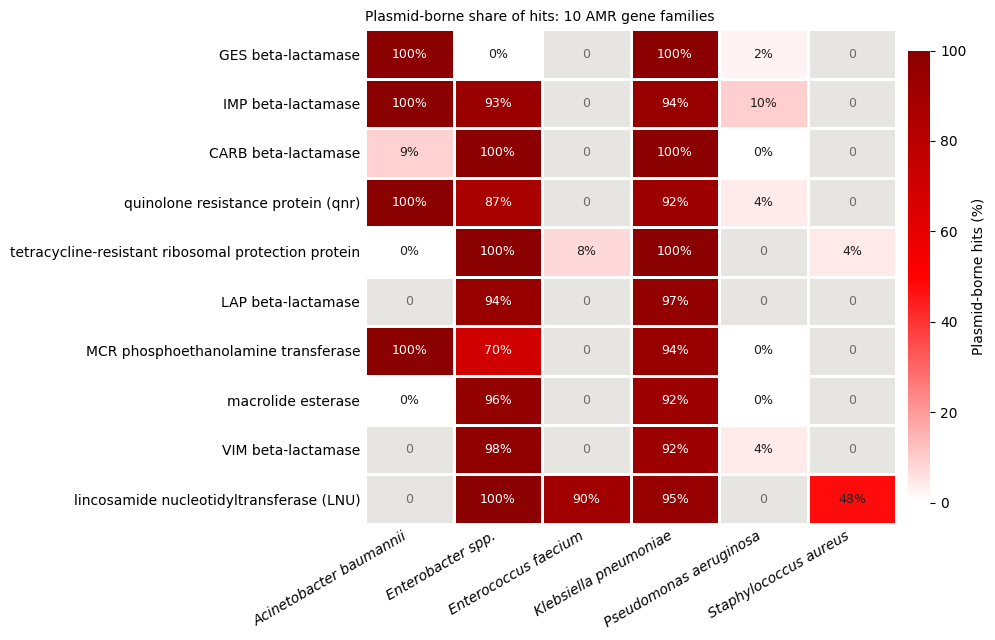

Saved heatmap -> /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Figures/ESKAPE_ARG_Plasmid_Pct_Heatmap_Top10_1.png


In [6]:
# --- Heatmap of a 10-family subset: share of each family's hits that are plasmid-borne, per organism ---
# Self-contained: reads the two matrices written by the cells above from disk.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Saving-path configuration
RESULTS_DIR = '/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Results/Mobsuite'
FIGURES_DIR = '/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/Figures'
PCT_MATRIX_CSV = os.path.join(RESULTS_DIR, 'ESKAPE_ARG_Plasmid_Pct_Matrix.csv')
MOBILITY_MATRIX_CSV = os.path.join(RESULTS_DIR, 'ESKAPE_ARG_Mobility_Matrix.csv')
SUBSET_CSV = os.path.join(RESULTS_DIR, 'ESKAPE_ARG_Plasmid_Pct_Top10_Variable.csv')
SUBSET_PNG = os.path.join(FIGURES_DIR, 'ESKAPE_ARG_Plasmid_Pct_Heatmap_Top10_1.png')
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

TOP_N = 10            # number of families shown
MIN_TOTAL_HITS = 100  # skip families with fewer hits; percentages from 1-2 genes are unstable

# Load data
pct = pd.read_csv(PCT_MATRIX_CSV, index_col=0)
mobility = pd.read_csv(MOBILITY_MATRIX_CSV, header=[0, 1], index_col=0).drop(index='Total', errors='ignore')
organisms = list(pct.columns)

# Hits per family per organism (chromosomal + every plasmid mobility class)
hits = pd.DataFrame({org: mobility[org].fillna(0).sum(axis=1) for org in organisms}).reindex(pct.index).fillna(0)
total_hits = hits.sum(axis=1)

# Families whose plasmid % differs most between organisms (standard deviation across the organisms)
eligible = pct.loc[total_hits >= MIN_TOTAL_HITS]
top_families = eligible.std(axis=1).sort_values(ascending=False).head(TOP_N).index

# In the full matrix, 0 means both "all hits chromosomal" and "family not found in this organism".
# Keep them apart: not-detected cells become NaN (blank in the CSV, grey "n.d." in the heatmap).
subset = pct.loc[top_families].where(hits.loc[top_families] > 0)

subset_out = subset.copy()
subset_out['total_hits'] = total_hits.loc[top_families].astype(int)
subset_out.to_csv(SUBSET_CSV)
print(f"Saved {len(subset)} families -> {SUBSET_CSV}")
"""
# Heatmap: single-hue sequential scale (light = 0%, dark = 100%), grey = not detected
#cmap = LinearSegmentedColormap.from_list(
    'plasmid_pct', ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])
#cmap.set_bad('#e6e5e1')
"""
cmap = LinearSegmentedColormap.from_list(
    'white_to_red', ['#ffffff', '#ff0000', '#8b0000']
)

# Keep the missing/not detected data colored grey
cmap.set_bad('#e6e5e1')
fig, ax = plt.subplots(figsize=(10, 6.5))
mesh = ax.pcolormesh(np.ma.masked_invalid(subset.values), cmap=cmap, vmin=0, vmax=100,
                     edgecolors='white', linewidth=2)
ax.invert_yaxis()

for i in range(subset.shape[0]):
    for j in range(subset.shape[1]):
        value = subset.iat[i, j]
        if pd.isna(value):
            label, color = '0', '#6b6a66'
        else:
            label, color = f'{value:.0f}%', ('white' if value >= 55 else '#1d1d1b')
        ax.text(j + 0.5, i + 0.5, label, ha='center', va='center', fontsize=9, color=color)

ax.set_xticks(np.arange(len(organisms)) + 0.5)
ax.set_xticklabels(organisms, rotation=30, ha='right', fontstyle='italic')
ax.set_yticks(np.arange(len(subset)) + 0.5)
ax.set_yticklabels(subset.index)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(mesh, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label('Plasmid-borne hits (%)')
cbar.outline.set_visible(False)

ax.set_title(f'Plasmid-borne share of hits: 10 AMR gene families',
             loc='left', fontsize=10)

plt.tight_layout()
plt.savefig(SUBSET_PNG, dpi=300, bbox_inches='tight')
plt.show()
print(f"Saved heatmap -> {SUBSET_PNG}")

## Heatmap

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Load data
pct = pd.read_csv(PCT_MATRIX_CSV, index_col=0)
mobility = pd.read_csv(MOBILITY_MATRIX_CSV, header=[0, 1], index_col=0).drop(index='Total', errors='ignore')
organisms = list(pct.columns)
